# 01 - Data and Preprocessing

This notebook turns the raw EEG file into the inputs every model uses. It runs
once and writes a cache (`data/epochs.npz`) that notebooks `02`-`06` load.

**The dataset.** 121 participants (61 ADHD, 60 control), 19 EEG channels placed
by the international 10-20 system, sampled at 128 Hz during a visual attention
task. The file has one row per sample: 19 amplitude columns plus `ID` and
`Class`. Source: the Kaggle dataset *EEG Dataset for ADHD*, file `adhdata.csv`
(not redistributed here - see `Project dataset.pdf`).

**What happens to it, in order:**

1. Load and inspect - how many subjects, how long each recording is
2. Band-pass filter each subject's signal (1-45 Hz)
3. Cut each recording into 2-second windows ("epochs")
4. Compute 456 features per epoch - band powers and friends
5. Save epochs + features + labels + subject IDs to the cache
6. Sanity-check that the features carry signal

> **Where this fits.** The project is a four-stage progression, every stage
> evaluated the same way so the numbers are directly comparable:
>
> | | Notebook | Stage |
> |---|---|---|
> | 01 | Data and preprocessing | shared by all models |
> | 02 | Logistic Regression | **Stage 1 - Basic** |
> | 03 | Logistic Regression + PCA | **Stage 1 - Basic** |
> | 04 | Random Forest | **Stage 2 - Bagging** |
> | 05 | XGBoost | **Stage 3 - Boosting** |
> | 06 | CNN + LSTM | **Stage 4 - Deep Learning** |
> | 07 | Model comparison | summary |
>
> Run `01` once first - it builds the cache every model notebook loads.

In [1]:
%matplotlib inline
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import butter, sosfiltfilt, welch, sosfreqz
from scipy.stats import skew, kurtosis, mannwhitneyu

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

CSV, CACHE = "data/adhdata.csv", "data/epochs.npz"
SF = 128                                   # sampling rate, Hz
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
os.makedirs("data", exist_ok=True)

## Step 1 - Load and inspect

**What this does.** Reads the CSV and answers the questions that shape every
later decision: how many subjects, how balanced the classes are, and how long
each recording is.

**Why recording length matters.** If recordings vary a lot in length, a
row-level split or a row-level accuracy is dominated by whoever was recorded
longest. That is one of the reasons every model here is scored per *subject*.

loaded data/adhdata.csv in 8 s
rows x columns : (2166383, 21)
channels       : Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T7 T8 P7 P8 Fz Cz Pz


missing values : 0



subjects       : 121  ({'ADHD': 61, 'Control': 60})


rows per class : {'ADHD': 1207069, 'Control': 959314}

recording length per subject (seconds):


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ADHD,61.0,155.0,58.0,73.0,112.0,144.0,185.0,338.0
Control,60.0,125.0,30.0,62.0,105.0,122.0,139.0,203.0


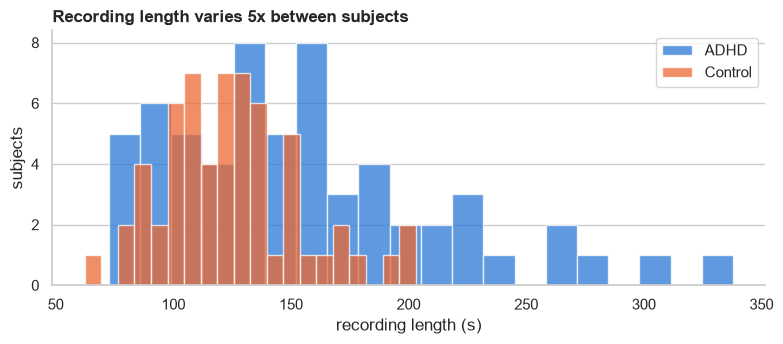

Note: rows are 56% ADHD but subjects are 61/60 - the row imbalance comes from
ADHD recordings being longer on average, not from more ADHD participants.


In [2]:
t0 = time.time()
df = pd.read_csv(CSV)
CH = [c for c in df.columns if c not in ("ID", "Class")]
print("loaded %s in %.0f s" % (CSV, time.time() - t0))
print("rows x columns :", df.shape)
print("channels       :", " ".join(CH))
print("missing values :", int(df.isnull().sum().sum()))

per_subj = df.groupby("ID").agg(label=("Class", "first"), rows=("Class", "size"))
per_subj["seconds"] = per_subj.rows / SF
print("\nsubjects       : %d  (%s)" % (len(per_subj), per_subj.label.value_counts().to_dict()))
print("rows per class :", df.Class.value_counts().to_dict())
print("\nrecording length per subject (seconds):")
display(per_subj.groupby("label").seconds.describe().round(0))

fig, ax = plt.subplots(figsize=(8, 3.6))
for lab, col in (("ADHD", BLUE), ("Control", ORANGE)):
    ax.hist(per_subj.loc[per_subj.label == lab, "seconds"], bins=20, alpha=.75, color=col, label=lab)
ax.set_xlabel("recording length (s)"); ax.set_ylabel("subjects")
ax.set_title("Recording length varies 5x between subjects", weight="bold", loc="left")
ax.legend(); ax.grid(axis="x", visible=False)
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

print("Note: rows are %.0f%% ADHD but subjects are %d/%d - the row imbalance comes from"
      % (100 * (df.Class == "ADHD").mean(), (per_subj.label == "ADHD").sum(), (per_subj.label == "Control").sum()))
print("ADHD recordings being longer on average, not from more ADHD participants.")

## Step 2 - Band-pass filter, 1-45 Hz

**What this does.** Applies a 4th-order Butterworth band-pass to each subject's
19-channel recording, forwards and backwards (`sosfiltfilt`), so the filter
adds no time shift.

**Why these edges.** Below 1 Hz lives slow drift from electrode contact and
sweat, not brain activity. Above 45 Hz the signal is dominated by muscle
artefact and 50 Hz mains interference. Everything the models use - delta
through gamma - sits inside 1-45 Hz.

**Why per subject.** Filtering is applied to one continuous recording at a
time, so no sample from one person ever influences another's filtered signal.

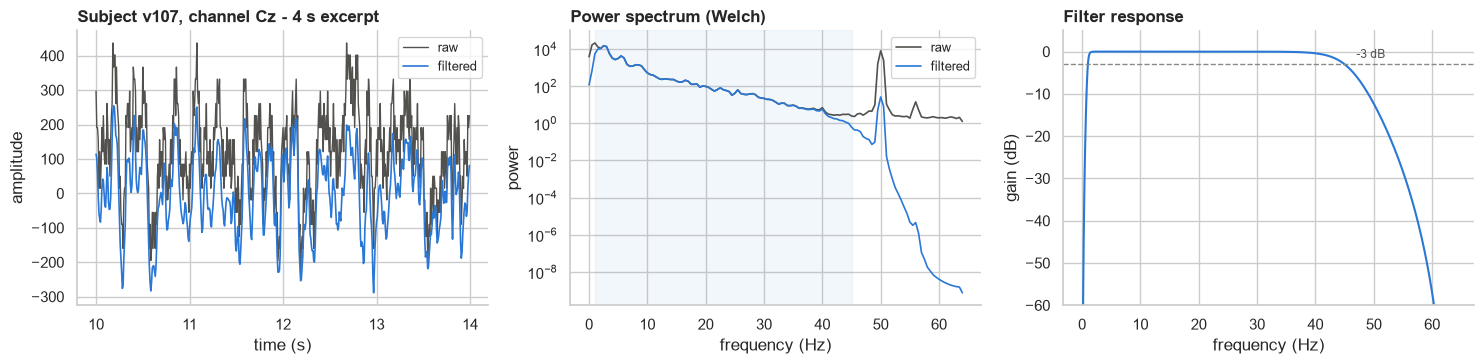

In [3]:
sos = butter(4, [1, 45], btype="bandpass", fs=SF, output="sos")

# show it on one subject, one channel
sid = per_subj.index[0]
raw = df.loc[df.ID == sid, CH].to_numpy(float)
filt = sosfiltfilt(sos, raw, axis=0)
t = np.arange(len(raw)) / SF
seg = slice(10 * SF, 14 * SF)                      # a 4-second excerpt
ch = CH.index("Cz")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(t[seg], raw[seg, ch], lw=1, color=MUTED, label="raw")
ax[0].plot(t[seg], filt[seg, ch], lw=1.2, color=BLUE, label="filtered")
ax[0].set_title("Subject %s, channel Cz - 4 s excerpt" % sid, weight="bold", loc="left")
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("amplitude"); ax[0].legend(fontsize=9)

f, P_raw = welch(raw[:, ch], fs=SF, nperseg=256)
_, P_flt = welch(filt[:, ch], fs=SF, nperseg=256)
ax[1].semilogy(f, P_raw, color=MUTED, lw=1.2, label="raw")
ax[1].semilogy(f, P_flt, color=BLUE, lw=1.2, label="filtered")
for lo, hi in ((1, 45),): ax[1].axvspan(lo, hi, color=BLUE, alpha=.06)
ax[1].set_title("Power spectrum (Welch)", weight="bold", loc="left")
ax[1].set_xlabel("frequency (Hz)"); ax[1].set_ylabel("power"); ax[1].legend(fontsize=9)

w, h = sosfreqz(sos, worN=2048, fs=SF)
ax[2].plot(w, 20 * np.log10(np.abs(h) + 1e-12), color=BLUE, lw=1.5)
ax[2].axhline(-3, ls="--", lw=1, color="#8a8a85"); ax[2].text(47, -1.5, "-3 dB", fontsize=8.5, color=MUTED)
ax[2].set_ylim(-60, 5); ax[2].set_title("Filter response", weight="bold", loc="left")
ax[2].set_xlabel("frequency (Hz)"); ax[2].set_ylabel("gain (dB)")
for a in ax:
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

## Step 3 - Cut recordings into 2-second epochs

**What this does.** Slides a 256-sample (2 s) window along each filtered
recording in 128-sample (1 s) steps, so consecutive epochs overlap by half.

**Why epochs at all.** A single sample - one row of the CSV, 7.8 ms of brain
activity - carries almost no information about a person. Two seconds is long
enough to estimate how much power sits in each frequency band, and short enough
to yield many examples per subject (61 to 336).

**Why 50% overlap.** It doubles the number of epochs at little cost. Because
every epoch keeps its subject ID, the overlap can never leak across a
train/test split - all of a subject's epochs move together.

**One important consequence.** Overlapping epochs from the same person are
*near-duplicates*. 16,749 epochs is **not** 16,749 independent examples; for
anything decided per person there are only 121. Keep that in mind when a model
with huge capacity (boosting, deep nets) seems to have "plenty of data".

In [4]:
WIN, STEP = 2 * SF, SF          # 256 samples, 128-sample stride

def epochs_of(sig):
    """Yield (256, 19) windows from one subject's filtered signal."""
    for s in range(0, len(sig) - WIN + 1, STEP):
        yield sig[s:s + WIN]

n_ep = per_subj.rows.apply(lambda n: max(0, (n - WIN) // STEP + 1))
print("epochs per subject: min %d  median %d  max %d  -> total %d"
      % (n_ep.min(), n_ep.median(), n_ep.max(), n_ep.sum()))

epochs per subject: min 61  median 129  max 336  -> total 16749


## Step 4 - Features: what the classical models will see

**What this does.** Describes each 2-second epoch with 24 numbers per channel,
456 in total. All are standard EEG descriptors:

| Family | Count/ch | What it captures |
|---|---|---|
| Absolute band power: delta 1-4, theta 4-8, alpha 8-13, beta 13-30, gamma 30-45 Hz | 5 | how much activity in each rhythm (Welch PSD, 0.5 Hz resolution) |
| Relative band power (each band / total) | 5 | the *mix* of rhythms, independent of overall amplitude |
| Ratios: theta/beta, (theta+alpha)/beta, alpha/beta | 3 | the balance of slow vs fast activity |
| Spectral entropy | 1 | how spread out the spectrum is (noise-like vs rhythmic) |
| Spectral edge frequencies (50%, 95%) | 2 | below which frequency half / 95% of the power lies |
| Hjorth activity, mobility, complexity | 3 | variance, dominant frequency, and waveform complexity, in the time domain |
| Std, skewness, kurtosis, RMS, zero crossings | 5 | amplitude distribution and oscillation rate |

**Why the theta/beta ratio gets its own column.** It is the most-studied single
EEG marker associated with ADHD. Its reliability is disputed in the research
literature, and Step 6 checks which way it points in *this* dataset rather than
assuming the textbook direction.

**Why the deep model does not use these.** Stage 4 (`06`) reads the raw
(256 x 19) epoch and learns its own features; this table is for Stages 1-3.

In [5]:
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}

def hjorth(ep):
    d1, d2 = np.diff(ep, axis=0), np.diff(np.diff(ep, axis=0), axis=0)
    v0, v1, v2 = ep.var(axis=0) + 1e-12, d1.var(axis=0) + 1e-12, d2.var(axis=0) + 1e-12
    mob = np.sqrt(v1 / v0)
    return v0, mob, np.sqrt(v2 / v1) / mob

def features(ep):
    """ep: (256, 19) filtered epoch -> 456 features (24 families x 19 channels)."""
    f, P = welch(ep, fs=SF, nperseg=WIN, axis=0)          # P: (129 freqs, 19 ch)
    out, bp = [], {}
    for b, (lo, hi) in BANDS.items():
        bp[b] = P[(f >= lo) & (f < hi)].sum(axis=0); out.append(bp[b])
    tot = sum(bp.values()) + 1e-12
    out += [bp[b] / tot for b in BANDS]
    out += [bp["theta"] / (bp["beta"] + 1e-12),
            (bp["theta"] + bp["alpha"]) / (bp["beta"] + 1e-12),
            bp["alpha"] / (bp["beta"] + 1e-12)]
    Pn = P / (P.sum(axis=0, keepdims=True) + 1e-12)
    out.append(-(Pn * np.log(Pn + 1e-12)).sum(axis=0))
    cum = np.cumsum(Pn, axis=0)
    out += [f[np.argmax(cum >= q, axis=0)] for q in (0.5, 0.95)]
    out += list(hjorth(ep))
    out += [ep.std(axis=0), skew(ep, axis=0), kurtosis(ep, axis=0),
            np.sqrt((ep ** 2).mean(axis=0)),
            (np.diff(np.sign(ep - ep.mean(axis=0)), axis=0) != 0).sum(axis=0).astype(float)]
    return np.concatenate(out)

FAMILIES = (["abs_" + b for b in BANDS] + ["rel_" + b for b in BANDS]
            + ["theta_beta", "theta_alpha_beta", "alpha_beta", "spec_entropy", "edge_50", "edge_95",
               "hjorth_activity", "hjorth_mobility", "hjorth_complexity",
               "std", "skew", "kurtosis", "rms", "zero_cross"])
FEATURE_NAMES = ["%s@%s" % (fam, c) for fam in FAMILIES for c in CH]
assert len(FEATURE_NAMES) == 24 * 19 == len(features(filt[:WIN]))
print("%d feature families x %d channels = %d features" % (len(FAMILIES), len(CH), len(FEATURE_NAMES)))

24 feature families x 19 channels = 456 features


## Step 5 - Build the cache

**What this does.** For every subject: filter, cut into epochs, compute
features; then save four arrays -

| key | shape | used by |
|---|---|---|
| `Xr` | (epochs, 256, 19) raw filtered windows | notebook 06 |
| `Xf` | (epochs, 456) features | notebooks 02-05 |
| `y`  | (epochs,) 1 = ADHD, 0 = Control | all |
| `g`  | (epochs,) subject ID | all - this is what keeps the folds honest |

The cache is a few hundred megabytes and is excluded from git; it is cheap to
rebuild by re-running this notebook.

In [6]:
t0 = time.time()
Xr, Xf, ys, gs = [], [], [], []
for sid, grp in df.groupby("ID", sort=False):
    sig = sosfiltfilt(sos, grp[CH].to_numpy(float), axis=0)
    lab = int(grp.Class.iloc[0] == "ADHD")
    for ep in epochs_of(sig):
        Xr.append(ep.astype(np.float32)); Xf.append(features(ep)); ys.append(lab); gs.append(sid)

Xr, Xf = np.asarray(Xr, np.float32), np.asarray(Xf, np.float32)
y, g = np.asarray(ys, np.int8), np.asarray(gs)
np.savez_compressed(CACHE, Xr=Xr, Xf=Xf, y=y, g=g, feature_names=np.array(FEATURE_NAMES))
print("built in %.0f s" % (time.time() - t0))
print("raw epochs %s | features %s | %.1f%% of epochs are ADHD | %d subjects"
      % (Xr.shape, Xf.shape, 100 * y.mean(), len(np.unique(g))))
print("cache: %s (%.0f MB)" % (CACHE, os.path.getsize(CACHE) / 1e6))

built in 115 s
raw epochs (16749, 256, 19) | features (16749, 456) | 55.8% of epochs are ADHD | 121 subjects
cache: data/epochs.npz (182 MB)


## Step 6 - Do the features carry signal?

**What this does.** Before training anything, compares a few features between
the two groups *at the subject level* (one mean per person, so the test is on
121 independent values, not 16,749 correlated ones). A Mann-Whitney U test asks
whether the two groups' distributions differ.

**What to look for.** Several relative-power features and the theta/beta ratio
separate the groups at p < 0.05, so there is something to learn. Note the
*direction* of theta/beta in this dataset - it is the opposite of the commonly
quoted "elevated theta/beta in ADHD". That is a known inconsistency in the
literature, and a reminder to report what the data shows.

feature,ADHD_median,Control_median,direction,p_value
rel_delta,0.453900,0.480500,ADHD lower,0.007600
rel_theta,0.244100,0.238400,ADHD higher,0.313300
rel_alpha,0.129100,0.119900,ADHD higher,0.038800
rel_beta,0.135400,0.115500,ADHD higher,0.012900
rel_gamma,0.020500,0.018200,ADHD higher,0.006000
theta_beta,2.810900,3.604900,ADHD lower,0.008900
spec_entropy,3.043400,2.982300,ADHD higher,0.009800
hjorth_mobility,0.443100,0.432300,ADHD higher,0.021500


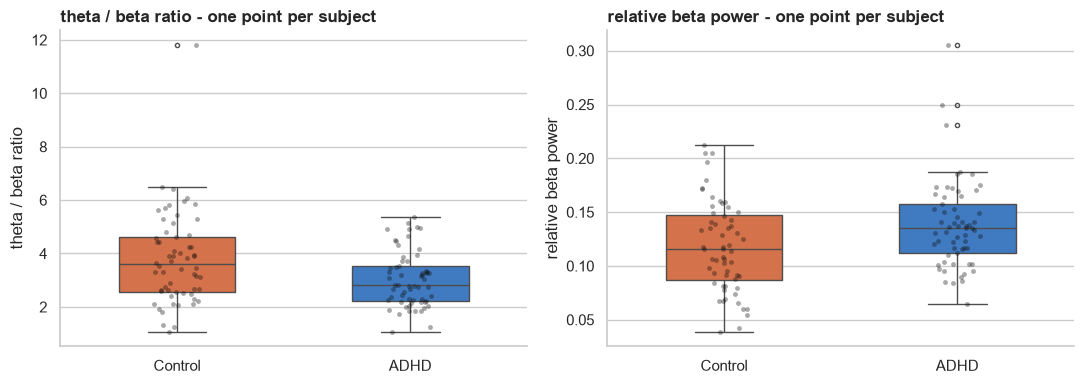

In [7]:
fam_idx = {fam: slice(i * 19, (i + 1) * 19) for i, fam in enumerate(FAMILIES)}
check = ["rel_delta", "rel_theta", "rel_alpha", "rel_beta", "rel_gamma", "theta_beta", "spec_entropy", "hjorth_mobility"]

subj_feat = pd.DataFrame({"ID": g, "y": y.astype(int)})
for fam in check:
    subj_feat[fam] = Xf[:, fam_idx[fam]].mean(axis=1)      # average over channels
subj_feat = subj_feat.groupby("ID").mean()

rows = []
for fam in check:
    a, c = subj_feat.loc[subj_feat.y == 1, fam], subj_feat.loc[subj_feat.y == 0, fam]
    rows.append(dict(feature=fam, ADHD_median=a.median(), Control_median=c.median(),
                     direction="ADHD higher" if a.median() > c.median() else "ADHD lower",
                     p_value=mannwhitneyu(a, c).pvalue))
display(pd.DataFrame(rows).round(4).style.hide(axis="index"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, fam, ttl in ((ax[0], "theta_beta", "theta / beta ratio"), (ax[1], "rel_beta", "relative beta power")):
    sns.boxplot(data=subj_feat, x="y", y=fam, hue="y", palette=[ORANGE, BLUE], legend=False,
                width=.5, fliersize=3, ax=a)
    sns.stripplot(data=subj_feat, x="y", y=fam, color=INK, alpha=.35, size=3.5, ax=a)
    a.set_xticks([0, 1], ["Control", "ADHD"]); a.set_xlabel(""); a.set_ylabel(ttl)
    a.set_title("%s - one point per subject" % ttl, weight="bold", loc="left")
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

## Summary

- 2.17 million rows became **16,749 two-second epochs** from **121 subjects**,
  each epoch tagged with its subject so later splits can be kept honest.
- Signals are band-passed to 1-45 Hz; 456 standard spectral and time-domain
  features describe each epoch for the classical models, while the deep model
  gets the raw filtered window.
- Group differences exist at the subject level, so classification is feasible -
  but with 121 people the effective sample is small, which every later notebook
  reports as a spread across folds rather than a single number.

Next: `02_Logistic_Regression.ipynb`, the Stage 1 baseline.